## Scope of notebook: to create automated bigwig quality annotations.

This is for bigwigs producing ATAC-seq libraries on human cell-lines. We can use a neural network based peak-caller as a proxy to determine the bigwig quality. If the resulting library of peak calls is of a high quality then this indicates a high quality bigwig.

In [1]:
from glob import glob
from intervaltree import IntervalTree
from os import path
from pysam import FastaFile
from sklearn.datasets import make_regression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyBigWig, random, shap, warnings, json
import seaborn as sns
import xgboost as xgb

# Load in covariates

In [2]:
covariate_glob = glob("../02_summary_JSONs/*.json")

covariate_data = []
for filepath in covariate_glob:
    collection_name = path.basename(filepath).split(".")[0]
    experiment_name = path.basename(filepath).split(".")[1]
    
    with open(filepath, "r", encoding="utf-8") as file:
        summary = json.load(file)

    summary["collection_name"] = collection_name
    summary["experiment_name"] = experiment_name
    
    covariate_data.append(summary)

print("Loading into dataframe")
covariate_data = pd.DataFrame(covariate_data)
covariate_columns = [col for col in covariate_data.columns if col not in ["collection_name", "experiment_name"]]

covariate_data.head()

Loading into dataframe


,mean_peak_score,median_peak_length,mean_shape_score,mean_peak_length,mean_enrichment_score,median_enrichment_score,lower_quartile_enrichment_score,upper_quartile_enrichment_score,percentage_coverage,percentage_coverage_0_5,percentage_coverage_0_95,n_peaks,n_peaks_0_5,n_peaks_0_95,total_bigwig_sum,collection_name,experiment_name
0,0.160475,1.275798e-07,0.095718,421.364203,0.470927,0.282173,0.076822,1.000000,0.266788,0.174855,0.157338,162563,25904,20001,75307455,calderon,1003-Mem_B-S
1,0.015679,9.270141e-08,0.006671,383.394778,0.154826,0.052373,0.015163,0.087784,0.521477,0.102927,0.074055,428185,6377,3682,30515307,H1_hESCs,ATAC_hESC_B
2,0.511913,6.424571e-01,0.410555,696.276942,0.655550,1.000000,0.079209,1.000000,0.559792,0.532850,0.521577,78883,40546,34613,89965212,calderon,1001-Th17_precursors-U
3,0.953873,9.998891e-01,0.986161,753.727101,0.382978,0.117275,0.020265,0.960515,0.319398,0.316747,0.308844,84218,81122,75068,1000000,catlas_fetal,Alveolar_Epithelial_1
4,0.983032,9.999388e-01,0.971215,586.811934,0.974313,1.000000,1.000000,1.000000,0.576878,0.576128,0.574101,58655,57830,56513,999748,catlas_adult,Beta_1


# Load target data

In [3]:
covariate_glob = glob("../03_targets/*.tsv")

target_data = pd.concat([pd.read_csv(x, sep="\t") for x in covariate_glob])
target_data[target_data.collection_name=="catlas_fetal"].head()

target_data.shape

(502, 8)

# Load into single dataframe + initial plots

In [4]:
full_model_data = covariate_data.merge(target_data, on=["experiment_name", "collection_name"], )

full_model_data.shape

(502, 23)

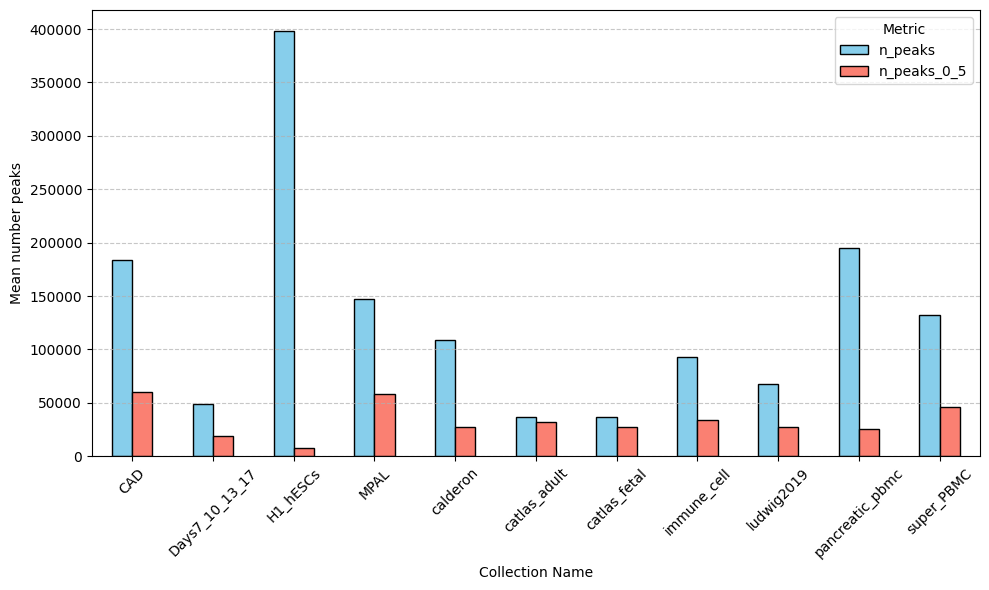

In [5]:
# Calculate the standard deviations
std_n_peaks = full_model_data.groupby("collection_name", observed=True)["n_peaks"].mean().reset_index()
std_n_peaks_0_5 = full_model_data.groupby("collection_name", observed=True)["n_peaks_0_5"].mean().reset_index()

# Merge the results for plotting
std_combined = pd.merge(std_n_peaks, std_n_peaks_0_5, on="collection_name", suffixes=("_n_peaks", "_n_peaks_0_5"))

# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Plot on the provided axis
std_combined.plot(
    x="collection_name",
    y=["n_peaks", "n_peaks_0_5"],
    kind="bar",
    color=["skyblue", "salmon"],
    edgecolor="black",
    ax=ax
)

# Customize the plot
ax.set_xlabel("Collection Name")
ax.set_ylabel("Mean number peaks")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", linestyle="--", alpha=0.7)
ax.legend(title="Metric", labels=["n_peaks", "n_peaks_0_5"])

plt.tight_layout()
plt.show()

# plt.savefig("01_plots/peaks_mean.pdf", format="pdf", bbox_inches='tight', dpi=300)
# plt.savefig("01_plots/peaks_mean.png", format="png", bbox_inches='tight', dpi=300)

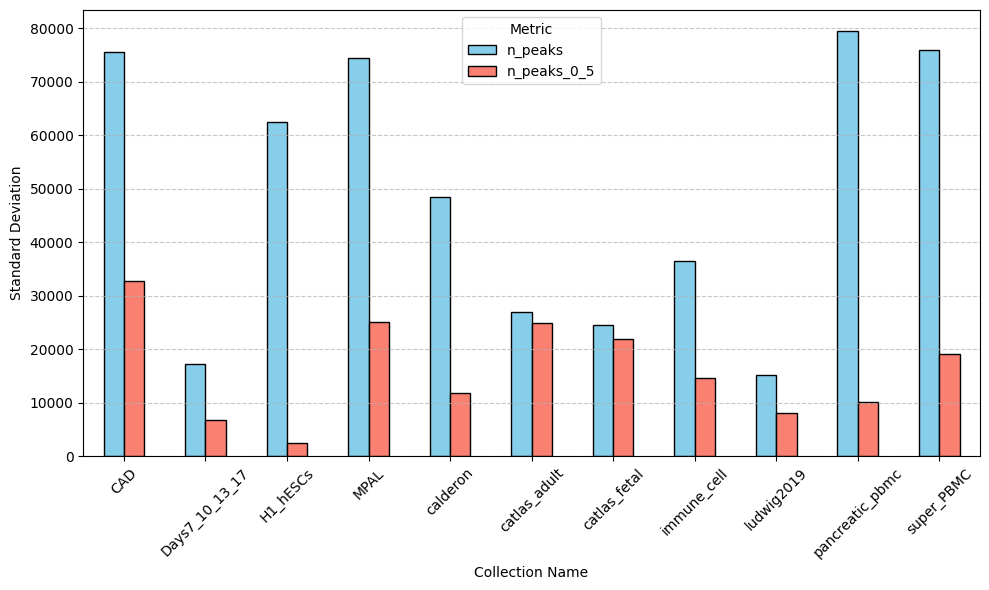

In [6]:
# Calculate the standard deviations
std_n_peaks = full_model_data.groupby("collection_name", observed=True)["n_peaks"].std().reset_index()
std_n_peaks_0_5 = full_model_data.groupby("collection_name", observed=True)["n_peaks_0_5"].std().reset_index()

# Merge the results for plotting
std_combined = pd.merge(std_n_peaks, std_n_peaks_0_5, on="collection_name", suffixes=("_n_peaks", "_n_peaks_0_5"))

# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Plot on that axis
std_combined.plot(
    x="collection_name",
    y=["n_peaks", "n_peaks_0_5"],
    kind="bar",
    color=["skyblue", "salmon"],
    edgecolor="black",
    ax=ax
)

# Customize the plot
ax.set_xlabel("Collection Name")
ax.set_ylabel("Standard Deviation")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", linestyle="--", alpha=0.7)
ax.legend(title="Metric", labels=["n_peaks", "n_peaks_0_5"])

plt.tight_layout()
plt.show()

# plt.savefig("01_plots/peaks_std.png", format="png", bbox_inches='tight', dpi=300)
# plt.savefig("01_plots/peaks_std.pdf", format="pdf", bbox_inches='tight', dpi=300)

# Train model

Mean Squared Error: 111596.02
R-squared: 0.9657


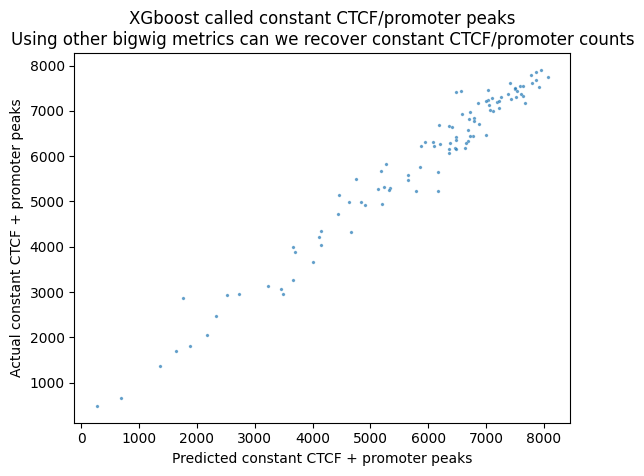

In [7]:
warnings.filterwarnings("ignore", category=FutureWarning, module="xgboost")

X = full_model_data[covariate_columns]
y = full_model_data.n_ctcf + full_model_data.n_promoters

# 2. Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the XGBoost regressor
model = xgb.XGBRegressor(objective='reg:squarederror')
model.fit(X_train, y_train)

# 4. Make predictions
y_pred = model.predict(X_test)

# 5. Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.4f}")

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.7,
    s=6,
)

plt.title("XGboost called constant CTCF/promoter peaks\nUsing other bigwig metrics can we recover constant CTCF/promoter counts")
plt.xlabel("Predicted constant CTCF + promoter peaks")
plt.ylabel("Actual constant CTCF + promoter peaks")
plt.show()

In [8]:
# Fit the basic structure for the model
param_grid = {
    "n_estimators": [10, 25, 50, 100, 150, 200],
    "learning_rate": [0.05, 0.1, 0.2]
}

grid_search = GridSearchCV(
    estimator=xgb.XGBRegressor(objective="reg:squarederror", random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)

grid_search.fit(X_train, y_train)
print("Best parameters:", grid_search.best_params_)

learning_rate = grid_search.best_params_["learning_rate"]
n_estimators = grid_search.best_params_["n_estimators"]

Best parameters: {'learning_rate': 0.1, 'n_estimators': 100}


In [10]:
param_grid = {
    "max_depth": [2, 3, 4],
    "min_child_weight": [2, 3, 4],
    "gamma": [0, 0.05, 0.1],
    "subsample": [0.6, 0.8, 0.9],
    "colsample_bytree": [0.8, 0.9, 1.0]
}

grid_search = GridSearchCV(
    estimator=xgb.XGBRegressor(
        objective="reg:squarederror",
        learning_rate=learning_rate,
        n_estimators=n_estimators,
        random_state=42
    ),
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)

grid_search.fit(X_train, y_train)
print("Best parameters:", grid_search.best_params_)

Best parameters: {'colsample_bytree': 1.0, 'gamma': 0, 'max_depth': 4, 'min_child_weight': 2, 'subsample': 0.6}


In [11]:
param_grid = {
    "reg_alpha": [0, 0.05, 0.1],
    "reg_lambda": [0.05, 0.1, 0.5, 1]
}

grid_search = GridSearchCV(
    estimator=xgb.XGBRegressor(
        objective="reg:squarederror",
        learning_rate=learning_rate,
        n_estimators=n_estimators,
        
        colsample_bytree=1.0,
        gamma=0.0,
        max_depth=4,
        min_child_weight=2,
        subsample=0.6,
        random_state=42
    ),
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)

grid_search.fit(X_train, y_train)
print("Best parameters:", grid_search.best_params_)

Best parameters: {'reg_alpha': 0.1, 'reg_lambda': 0.5}


Mean Squared Error: 106828.84
R-squared: 0.9672


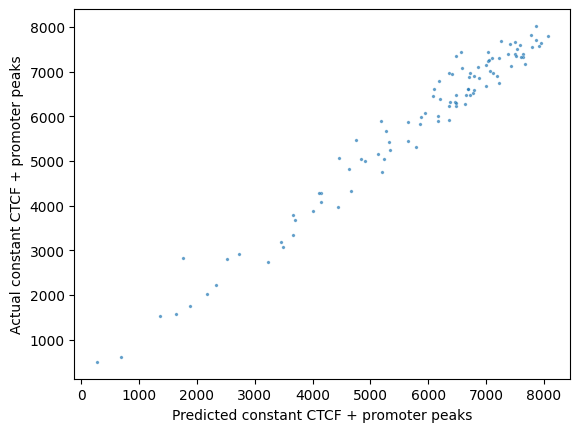

In [12]:
# Final model

model = grid_search.best_estimator_

# 4. Make predictions
y_pred = model.predict(X_test)

# 5. Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.4f}")

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.7,
    s=6,
)

# plt.title("XGboost called constant CTCF/promoter peaks\nUsing other bigwig metrics can we recover constant CTCF/promoter counts")
plt.xlabel("Predicted constant CTCF + promoter peaks")
plt.ylabel("Actual constant CTCF + promoter peaks")

# plt.savefig("01_plots/xgboost_predictions.pdf", format="pdf", bbox_inches='tight', dpi=300)
# plt.savefig("01_plots/xgboost_predictions.png", format="png", bbox_inches='tight', dpi=300)
plt.show()

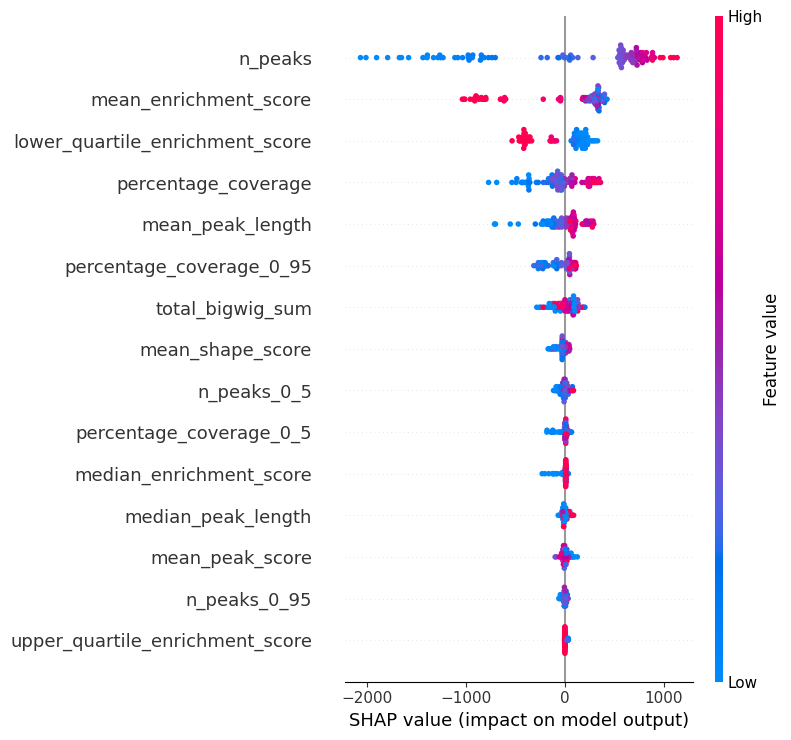

In [13]:
exp = shap.TreeExplainer(grid_search.best_estimator_)
shap_values = exp.shap_values(X_test, y_test)
shap.summary_plot(shap_values, X_test, show=False)

# plt.savefig("01_plots/shap_summary_plot.pdf", format="pdf", bbox_inches='tight', dpi=300)
# plt.savefig("01_plots/shap_summary_plot.png", format="png", bbox_inches='tight', dpi=300)
plt.show()

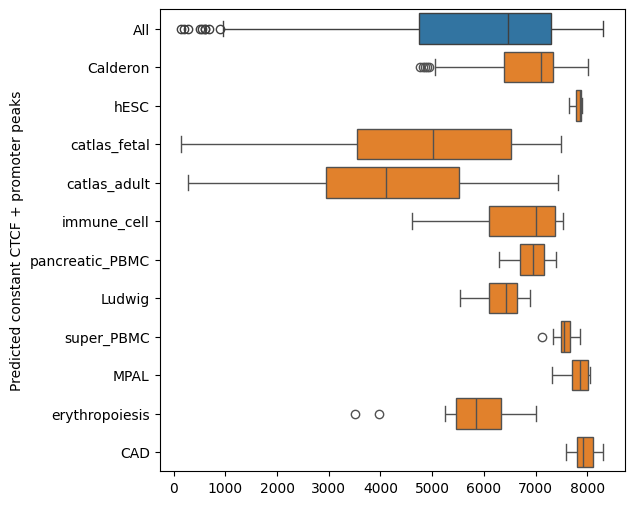

In [14]:
# Create a NumPy array (example)
# data = np.random.normal(loc=0, scale=1, size=100)  # 100 random values from a normal distribution
boxplots = pd.DataFrame()
boxplots["prediction"] = model.predict(X)
boxplots["collection"] = full_model_data.collection_name
boxplots['collection'] = boxplots['collection'].replace('calderon', 'Calderon')
boxplots['collection'] = boxplots['collection'].replace('H1_hESCs', 'hESC')
boxplots['collection'] = boxplots['collection'].replace('pancreatic_pbmc', 'pancreatic_PBMC')
boxplots['collection'] = boxplots['collection'].replace('ludwig2019', 'Ludwig')
boxplots['collection'] = boxplots['collection'].replace('Days7_10_13_17', 'erythropoiesis')

all_data = boxplots.copy()
all_data['collection'] = 'All'

plot_data = pd.concat([boxplots, all_data])
# data = model.predict(X)

plt.figure(figsize=(6, 6))  # Adjust as needed

# Create a boxplot using Seaborn
sns.boxplot(x="prediction", y="collection", data=all_data)
sns.boxplot(x="prediction", y="collection", data=boxplots)
plt.ylabel("Predicted constant CTCF + promoter peaks")
plt.xlabel("")
# plt.tight_layout()

# Add a title (optional)
# plt.title("Boxplot of NumPy Array")

# Show the plot
# plt.savefig("01_plots/Boxplot_results_2.pdf", format="pdf", bbox_inches='tight', dpi=300)
# plt.savefig("01_plots/Boxplot_results_2.png", format="png", bbox_inches='tight', dpi=300)
plt.show()

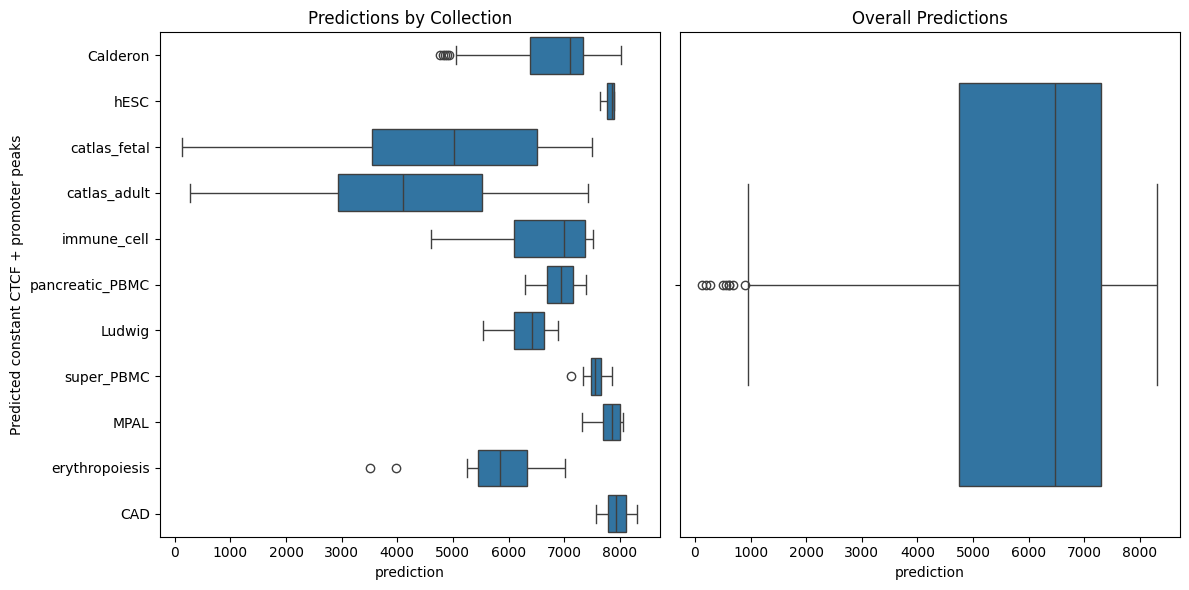

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Grouped box plots
sns.boxplot(y="collection", x="prediction", data=boxplots, ax=axes[0])
axes[0].set_ylabel("Predicted constant CTCF + promoter peaks")
axes[0].set_title("Predictions by Collection")

# Overall box plot
sns.boxplot(x="prediction", data=boxplots, ax=axes[1])
axes[1].set_title("Overall Predictions")

plt.tight_layout()
plt.show()

In [16]:
data = all_data.prediction

# Calculate quartiles and median
q1 = np.percentile(data, 25)
median = np.median(data)
q3 = np.percentile(data, 75)

# Calculate interquartile range (IQR)
iqr = q3 - q1

# Calculate whiskers (1.5 * IQR rule)
lower_whisker = q1 - 1.5 * iqr
upper_whisker = q3 + 1.5 * iqr

# Find outliers
outliers = data[(data < lower_whisker) | (data > upper_whisker)]

# Print the values
print("Box Values:")
print(f"Lower Quartile (Q1): {q1:.2f}")
print(f"Median (Q2): {median:.2f}")
print(f"Upper Quartile (Q3): {q3:.2f}")

print("\nWhisker Values:")
print(f"Lower Whisker: {lower_whisker:.2f}")
print(f"Upper Whisker: {upper_whisker:.2f}")

print("\nOutliers:")
print(outliers)

Box Values:
Lower Quartile (Q1): 4754.02
Median (Q2): 6471.38
Upper Quartile (Q3): 7291.88

Whisker Values:
Lower Whisker: 947.22
Upper Whisker: 11098.67

Outliers:
10     206.486328
37     272.096100
57     901.855408
112    607.713867
152    691.845337
241    550.601013
289    502.204102
475    134.872177
497    610.885254
Name: prediction, dtype: float32


In [17]:
random.seed(42)

print("Good")
display(
    full_model_data.loc[
        random.sample(sorted(set(np.where((data > 7800))[0]).intersection(set(X_test.index))), 2)
    ][["collection_name", "experiment_name"]],
)
print("***\n\nAbove average")
display(
    full_model_data.loc[
        random.sample(sorted(set(np.where((data < q3) & (data > median ))[0]).intersection(set(X_test.index))), 2)
    ][["collection_name", "experiment_name"]],
)
print("***\n\nBelow average")
display(
    full_model_data.loc[
        random.sample(sorted(set(np.where((data > q1) & (data < median ))[0]).intersection(set(X_test.index))), 2)
    ][["collection_name", "experiment_name"]],
)
print("***\n\nBad")
display(
    full_model_data.loc[
        random.sample(sorted(set(np.where((data > 1000) & (data < 2000))[0]).intersection(set(X_test.index))), 2)
    ][["collection_name", "experiment_name"]],
)

Good


,collection_name,experiment_name
499,MPAL,05_CMP_LMPP
72,calderon,1001-Naive_Teffs-U


***

Above average


,collection_name,experiment_name
0,calderon,1003-Mem_B-S
463,ludwig2019,ProE2


***

Below average


,collection_name,experiment_name
148,catlas_fetal,Excitatory_Neuron_5
131,catlas_fetal,Macrophage_Hepatic_3


***

Bad


,collection_name,experiment_name
77,catlas_adult,Keratinocyte_2
442,catlas_adult,Endothelial_Exocrine


# covariate distribution plots

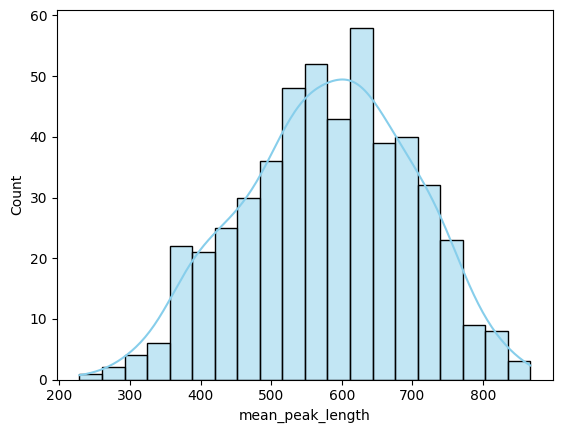

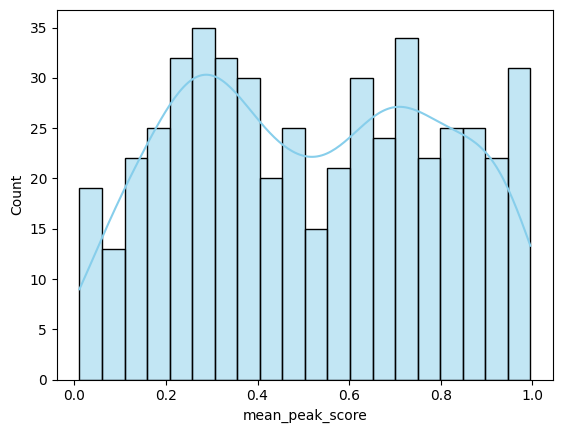

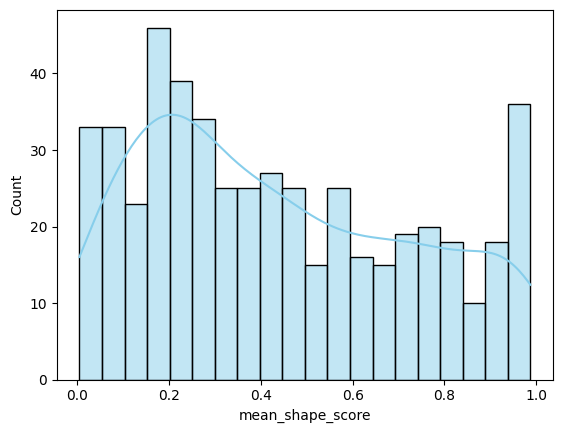

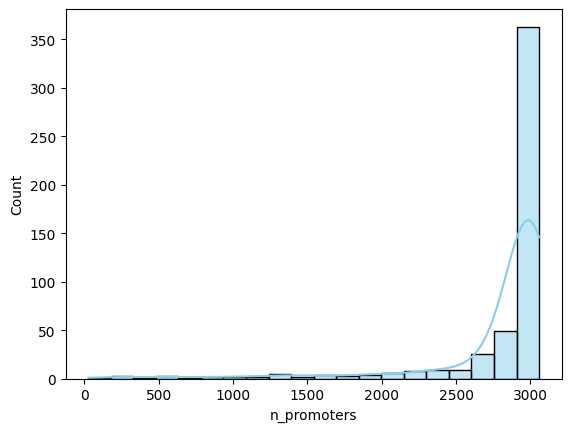

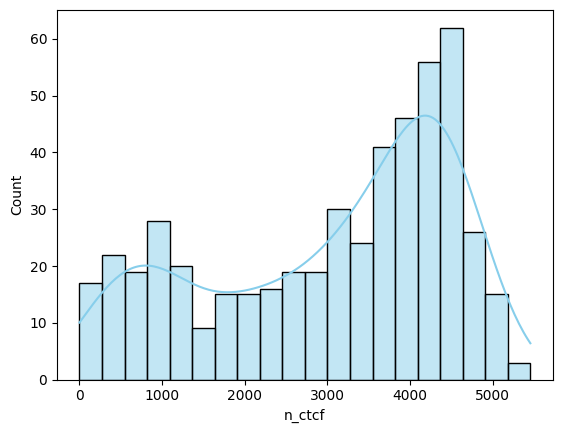

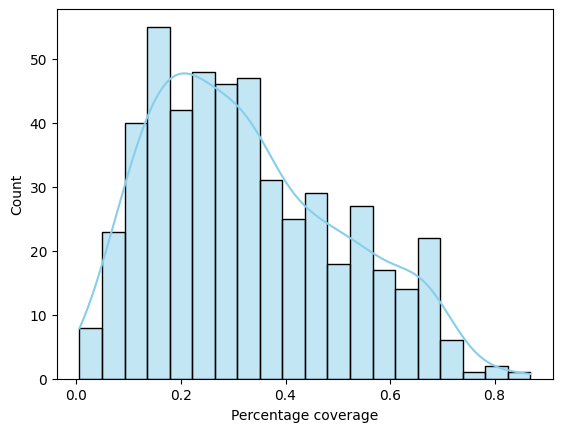

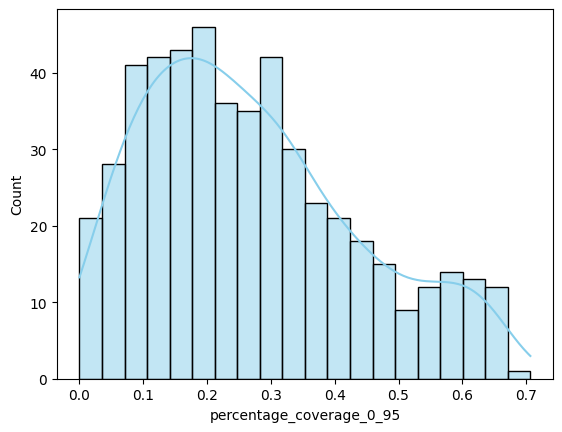

In [18]:
sns.histplot(
    data=full_model_data,
    x="mean_peak_length",
    bins=20,
    color="skyblue",
    kde=True,
)
# plt.title("Distribution of mean peak length")
# plt.savefig("01_plots/mean_peak_length.pdf", format="pdf", bbox_inches='tight', dpi=300)
# plt.savefig("01_plots/mean_peak_length.png", format="png", bbox_inches='tight', dpi=300)
plt.show()

sns.histplot(
    data=full_model_data,
    x="mean_peak_score",
    bins=20,
    color="skyblue",
    kde=True,
)
# plt.title("Distribution of mean peak score")
# plt.savefig("01_plots/mean_peak_score.pdf", format="pdf", bbox_inches='tight', dpi=300)
# plt.savefig("01_plots/mean_peak_score.png", format="png", bbox_inches='tight', dpi=300)

plt.show()

sns.histplot(
    data=full_model_data,
    x="mean_shape_score",
    bins=20,
    color="skyblue",
    kde=True,
)
# plt.title("Distribution of mean peak score")
# plt.savefig("01_plots/mean_shape_score.pdf", format="pdf", bbox_inches='tight', dpi=300)
# plt.savefig("01_plots/mean_shape_score.png", format="png", bbox_inches='tight', dpi=300)

plt.show()

sns.histplot(
    data=full_model_data,
    x="n_promoters",
    bins=20,
    color="skyblue",
    kde=True,
)
# plt.title("Distribution of number of peaks intersecting constant Promoters")
# plt.savefig("01_plots/promoters.pdf", format="pdf", bbox_inches='tight', dpi=300)
# plt.savefig("01_plots/promoters.png", format="png", bbox_inches='tight', dpi=300)

plt.show()

sns.histplot(
    data=full_model_data,
    x="n_ctcf",
    bins=20,
    color="skyblue",
    kde=True,
)
# plt.title("Distribution of number of peaks intersecting constant CTCF")
# plt.savefig("01_plots/ctcf.pdf", format="pdf", bbox_inches='tight', dpi=300)
# plt.savefig("01_plots/ctcf.png", format="png", bbox_inches='tight', dpi=300)

plt.show()


sns.histplot(
    data=full_model_data,
    x="percentage_coverage",
    bins=20,
    color="skyblue",
    kde=True,
)
plt.xlabel("Percentage coverage")
# plt.title("Distribution of percentage of reads coveraged by peaks")
# plt.savefig("01_plots/percentage_coverage.pdf", format="pdf", bbox_inches='tight', dpi=300)
# plt.savefig("01_plots/percentage_coverage.png", format="png", bbox_inches='tight', dpi=300)

plt.show()

sns.histplot(
    data=full_model_data,
    x="percentage_coverage_0_95",
    bins=20,
    color="skyblue",
    kde=True,
)
# plt.title("Distribution of percentage of reads coveraged by high confident peaks")
# plt.savefig("01_plots/percentage_coverage_0_95.pdf", format="pdf", bbox_inches='tight', dpi=300)
# plt.savefig("01_plots/percentage_coverage_0_95.png", format="png", bbox_inches='tight', dpi=300)

plt.show()

# summary_data.n_ctcf.hist(bins=30)

# Saving XGBoost model

In [19]:
model.save_model("../Model/model.json")

# Check loading XGBoost model

In [20]:
xgb_model_check = xgb.XGBRegressor(
    objective="reg:squarederror",

    # Best params from tuning
    learning_rate=0.1,
    n_estimators=100,

    max_depth=4,
    min_child_weight=2,
    subsample=0.6,
    colsample_bytree=1.0,
    gamma=0.0,

    reg_alpha=0.1,
    reg_lambda=0.5,

    # Reproducibility
    random_state=42,
    n_jobs=-1
)

In [21]:
xgb_model_check.load_model("../Model/model.json")

In [22]:
y_pred_check = xgb_model_check.predict(X_test)
y_pred_check.shape

(101,)

In [23]:
y_pred == y_pred_check

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True])